# Лабораторная работа №5: Ансамбли моделей

## Цель:
изучить принципы построения ансамблей моделей машинного обучения, освоить основные методы ансамблирования (Bagging, Random Forest, Gradient Boosting, Stacking), исследовать влияние их гиперпараметров на качество предсказаний и сравнить ансамблевые модели с отдельными алгоритмами машинного обучения.

---

Импорт библиотек

In [1]:
import time
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import (
    BaggingClassifier,
    GradientBoostingClassifier,
    RandomForestClassifier,
    StackingClassifier,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

---

### 1. Описание данных, разведочный анализ и предобработка

Источник: https://www.kaggle.com/datasets/rishabhrajsharma/intermediate-core-ml-assignment-dataset

Intermediate CoreML Assignment Dataset — это синтетический, но реалистичный набор аналитики клиентов, предназначенный для обучения и практики в области машинного обучения.

Он содержит как числовые, так и категориальные признаки, включает отсутствующие значения и предоставляет две цели:
- target_reg → регрессионная цель для линейной регрессии, градиентного спуска, регуляризации
- churn → несбалансированная бинарная цель для классификационных моделей

Признаки:

| Поле             | Описание                                            | Перевод |
|------------------|-----------------------------------------------------|---------|
| customer_id      | Unique customer identifier (do not use in training) | Уникальный идентификатор клиента (не использовать во время обучения) |
| age              | Customer age (years)                                | Возраст клиента (лет) |
| tenure_months    | Customer tenure in months                           | Срок сотрудничества с клиентом в месяцах |
| income           | Annual income (contains missing values)             | Годовой доход (содержит пропущенные значения) |
| credit_score     | Credit score 300–850 (contains missing values)      | Кредитный рейтинг 300–850 (содержит пропущенные значения) |
| monthly_charges  | Monthly service charge (contains missing values)    | Ежемесячная плата за обслуживание (содержит пропущенные значения) |
| support_tickets  | Number of support tickets raised                    | Количество обращений в службу поддержки |
| avg_session_time | Avg usage session time (minutes)                    | Среднее время сеанса использования (минуты) |
| late_payments    | Count of late payments                              | Количество просроченных платежей |
| gender           | Gender                                              | Пол |

In [2]:
df = pd.read_csv("C:\\Desktop\\Education\\5 семестр\\ML\\LW №5\\data\\intermediate_coreml_assignment_dataset.csv")

# проверим форму данных и типы
print("Размерность датасета:", df.shape)
df.info()
display(df.head())

Размерность датасета: (50000, 18)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        50000 non-null  int64  
 1   age                50000 non-null  int64  
 2   tenure_months      50000 non-null  int64  
 3   income             49305 non-null  float64
 4   credit_score       49183 non-null  float64
 5   monthly_charges    49171 non-null  float64
 6   support_tickets    50000 non-null  int64  
 7   avg_session_time   50000 non-null  float64
 8   late_payments      50000 non-null  int64  
 9   gender             49200 non-null  str    
 10  city_tier          50000 non-null  str    
 11  plan_type          50000 non-null  str    
 12  payment_method     49187 non-null  str    
 13  device_type        50000 non-null  str    
 14  has_international  50000 non-null  str    
 15  is_student         50000 non-null  str    
 16 

,customer_id,age,tenure_months,income,credit_score,monthly_charges,support_tickets,avg_session_time,late_payments,gender,city_tier,plan_type,payment_method,device_type,has_international,is_student,target_reg,churn
0,200001,51,6,23039.19,718.0,1065.30,0,28.36,0,Female,Tier1,Basic,UPI,Android,No,No,44030.77,0
1,200002,46,116,54173.02,491.0,1035.67,1,15.75,0,Male,Tier2,Basic,Card,Android,No,No,138673.42,0
2,200003,20,112,37130.61,623.0,897.50,1,15.15,0,Female,Tier1,Standard,Card,Android,No,No,159250.49,0
3,200004,18,53,39873.95,850.0,1095.42,3,26.83,0,Male,Tier1,Standard,UPI,Android,No,No,109410.17,1
4,200005,22,60,39591.09,779.0,1422.29,0,18.83,0,Male,Tier2,Premium,Card,Android,No,No,91008.23,0


Дубликатов в данных: 0

Пропуски по столбцам:
income             695
credit_score       817
monthly_charges    829
gender             800
payment_method     813
dtype: int64


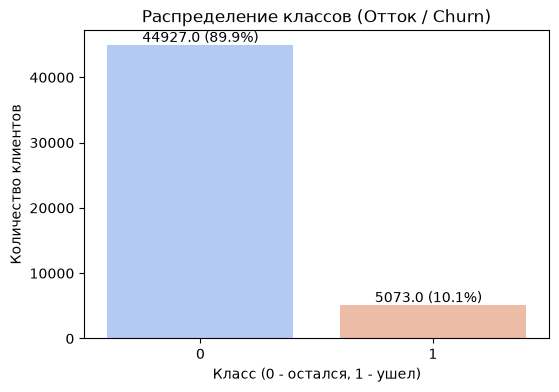

In [3]:
# проверка пропусков и дубликатов
print("Дубликатов в данных:", df.duplicated().sum())
print("\nПропуски по столбцам:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# анализ распределения целевой переменной (дисбаланс классов)
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x='churn', palette='coolwarm')
plt.title("Распределение классов (Отток / Churn)")
plt.xlabel("Класс (0 - остался, 1 - ушел)")
plt.ylabel("Количество клиентов")
for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df)*100:.1f}%)',
                (p.get_x() + 0.15, p.get_height() + 500))
plt.show()

In [4]:
# удаляем идентификатор и посторонний таргет
df_clean = df.drop(columns=["customer_id", "target_reg"])

# разделение на матрицу признаков X и целевой вектор y
X = df_clean.drop(columns=["churn"])
y = df_clean["churn"]

# определение списков числовых и категориальных признаков
num_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_features = X.select_dtypes(include=["object"]).columns.tolist()

print(f"Числовые признаки ({len(num_features)}): {num_features}")
print(f"Категориальные признаки ({len(cat_features)}): {cat_features}")

print("Описательные статистики числовых признаков:")
display(df[num_features].describe().T)

# разделение на train/test (80:20) со стратификацией (сохранение дисбаланса)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(
    f"Размерность Train: {X_train.shape}, Test: {X_test.shape}. "
    f"Доля класса 1 в train: {y_train.mean():.3f}, в test: {y_test.mean():.3f}"
)

Числовые признаки (8): ['age', 'tenure_months', 'income', 'credit_score', 'monthly_charges', 'support_tickets', 'avg_session_time', 'late_payments']
Категориальные признаки (7): ['gender', 'city_tier', 'plan_type', 'payment_method', 'device_type', 'has_international', 'is_student']
Описательные статистики числовых признаков:


,count,mean,std,min,25%,50%,75%,max
age,50000.0,41.216260,13.818791,18.0,29.000,41.00,53.00,65.00
tenure_months,50000.0,59.212880,34.976033,0.0,30.000,59.00,89.00,120.00
income,49305.0,44802.597299,14951.337403,8000.0,34744.270,44688.01,54330.26,92535.91
credit_score,49183.0,570.410691,159.033340,301.0,436.000,568.00,704.00,850.00
monthly_charges,49171.0,1196.449165,452.227406,200.0,887.335,1193.13,1509.64,2595.86
support_tickets,50000.0,1.183460,1.094361,0.0,0.000,1.00,2.00,5.00
avg_session_time,50000.0,18.018672,6.052666,2.0,13.880,18.09,22.20,36.53
late_payments,50000.0,0.257940,0.512028,0.0,0.000,0.00,0.00,3.00


Размерность Train: (40000, 15), Test: (10000, 15). Доля класса 1 в train: 0.101, в test: 0.102


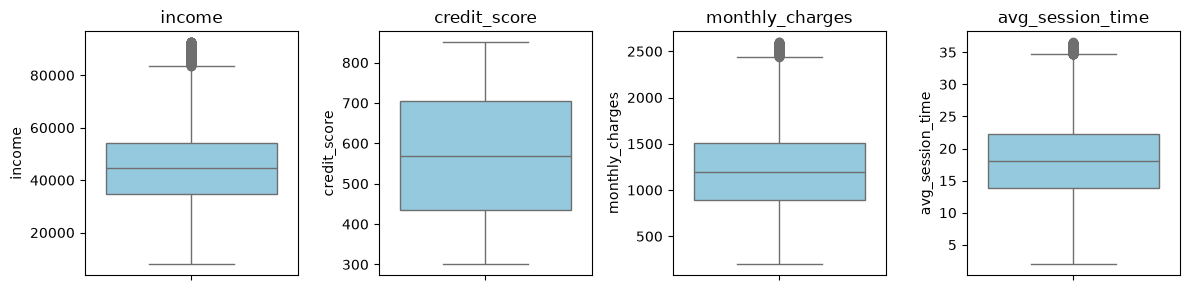

,Признак,Выбросов,"Доля, %"
0,income,357,0.71
1,credit_score,0,0.00
2,monthly_charges,203,0.41
3,avg_session_time,221,0.44
4,age,0,0.00
5,tenure_months,0,0.00


In [5]:
# анализ выбросов методом IQR и Boxplot
outlier_info = []
for col in [
    "income",
    "credit_score",
    "monthly_charges",
    "avg_session_time",
    "age",
    "tenure_months"
]:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    n_outliers = (
        (df_clean[col] < (Q1 - 1.5 * IQR)) | (df_clean[col] > (Q3 + 1.5 * IQR))
    ).sum()
    outlier_info.append(
        {
            "Признак": col,
            "Выбросов": n_outliers,
            "Доля, %": round((n_outliers / len(df_clean)) * 100, 2),
        }
    )

plt.figure(figsize=(12, 3))
for i, col in enumerate(
    ["income", "credit_score", "monthly_charges", "avg_session_time"], 1
):
    plt.subplot(1, 4, i)
    sns.boxplot(y=df_clean[col], color="skyblue")
    plt.title(col)
plt.tight_layout()
plt.show()

pd.DataFrame(outlier_info)

Про выбросы:
- В признаках income, monthly_charges и avg_session_time найдено менее 1% выбросов
- В признаках age, credit_score и tenure_months аномалий нет вообще (0%)
- Все значения укладываются в адекватные рамки (доходы до 92 тыс., чеки до 2.5 тыс.), удалять их не требуется - данные чистые и реалистичные

Наблюдения:
* Наблюдаем сильный дисбаланс классов (примерно 10% - отток, когда остальные 90% - лояльные клиенты), что усложнит нам задачу классификации
* Также наблюдаем, что числовые данные находятся в адекватных пределах, однако присутствуют пропуски
* Видим разницу в масштабе данных
* Замечаем из признака late_payments, что более 75% клиентов не имеют просрочек (min = 0, 25% = 0, 50% (медиана) = 0, 75% = 0, max = 3), следовательно можем предположить, что late_payments - это достаточно редкое событие и скорее всего тревожный сигнал для нашей задачи классификации

1. Предметная область и назначение данных:
Набор данных содержит аналитическую информацию о клиентах телекоммуникационной компании (демография, финансовые показатели, поведение, параметры тарифа и обращений в поддержку)

2. Характеристики выборки:
* Объем выборки: 50 000 строк, 18 исходных признаков
* Наличие пропусков: выявлены в признаках income, credit_score, monthly_charges, gender, payment_method
* Дубликаты: отсутствуют

3. Целевая переменная и постановка задачи:
* Целевая переменная: churn (бинарная: 0 - клиент остался, 1 - ушел в отток)
* Соотношение классов: 89.9% (0) к 10.1% (1) - выраженный дисбаланс классов
* Задача ML: бинарная классификация клиентов с высоким риском оттока
* Исключаемые признаки: customer_id (неинформативный ID) и target_reg (регрессионный таргет, утечка данных)

In [6]:
# создание единого трансформера данных (preprocessor)

# пайплайн для числовых признаков: медианная импутация + стандартизация
num_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# пайплайн для категориальных признаков: модальная импутация + One-Hot Encoding
cat_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore", drop="first", sparse_output=False
            ),
        ),
    ]
)

# объединение преобразований
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_features),
        ("cat", cat_transformer, cat_features),
    ]
)

# обучаем препроцессор строго на X_train
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# извлечение имен признаков после OHE
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["onehot"]
encoded_cat_names = cat_encoder.get_feature_names_out(
    cat_features
).tolist()
all_feature_names = num_features + encoded_cat_names
print(f"Всего признаков после кодирования: {len(all_feature_names)}")

# вспомогательная функция оценки качества
def evaluate_model(model, X_tr, y_tr, X_te, y_te, model_name="Model"): # обучает модель, замеряет время и вычисляет метрики для train и test
    start_time = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - start_time

    # предсказания
    y_tr_pred = model.predict(X_tr)
    y_te_pred = model.predict(X_te)

    metrics = {
        "Model": model_name,
        "Train_Accuracy": accuracy_score(y_tr, y_tr_pred),
        "Train_F1": f1_score(y_tr, y_tr_pred),
        "Accuracy": accuracy_score(y_te, y_te_pred),
        "Precision": precision_score(y_te, y_te_pred, zero_division=0),
        "Recall": recall_score(y_te, y_te_pred),
        "F1": f1_score(y_te, y_te_pred),
        "Fit_Time_sec": round(fit_time, 3),
    }
    return metrics



Всего признаков после кодирования: 21


---

### 2. Базовые одиночные модели

Обучение логистической регрессии и одиночного дерева решений

In [7]:
results_task2 = []

# LogisticRegression (логистическая регрессия)
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
results_task2.append(
    evaluate_model(
        log_reg,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name="Logistic Regression",
    )
)

# DecisionTreeClassifier (неограниченное дерево решений)
dt_default = DecisionTreeClassifier(random_state=RANDOM_STATE)
results_task2.append(
    evaluate_model(
        dt_default,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name="Decision Tree (Default)",
    )
)

df_task2 = pd.DataFrame(results_task2)
df_task2

,Model,Train_Accuracy,Train_F1,Accuracy,Precision,Recall,F1,Fit_Time_sec
0,Logistic Regression,0.89855,0.0,0.8985,0.000000,0.000000,0.000000,0.046
1,Decision Tree (Default),1.00000,1.0,0.8010,0.108434,0.133005,0.119469,0.356


1. Logistic Regression (проблема мажоритарного класса):
   - Модель показала Accuracy около 89.85%, однако метрики Precision, Recall и F1-score равны 0.0
   - Причина: из-за сильного дисбаланса классов (89.9% к 10.1%) и стандартного порога классификации 0.5 и модель просто всем предсказывает мажоритарный класс

2. Decision Tree Classifier (катастрофическое переобучение / High Variance):
   - На обучающей выборке дерево без ограничения глубины достигло идеальных значений (Accuracy = 1.0, F1 = 1.0).
   - На тестовой выборке качество обвалилось: Accuracy упала до 80.1% (что даже ниже доли мажоритарного класса), а F1-score составил всего 0.119
   - Причина: одиночное дерево решений делит пространство признаков до единичных объектов в листьях, заучивая статистический шум обучающей выборки вместо поиска общих закономерностей

Вывод: По отдельности базовые модели работают плохо: логистическая регрессия игнорирует меньший класс, а дерево переобучается. Поэтому дальше логично переходить к ансамблевым методам (Bagging, Random Forest, Boosting), которые помогают бороться с переобучением и смещением (систематический перекос модели в одну сторону: модель стабильно ошибается определённым образом, потому что она слишком простая и делает сильные допущения)

---

### 3. Bagging: объединение моделей

#### 3.1 Исследование влияния количества базовых моделей (n_estimators)

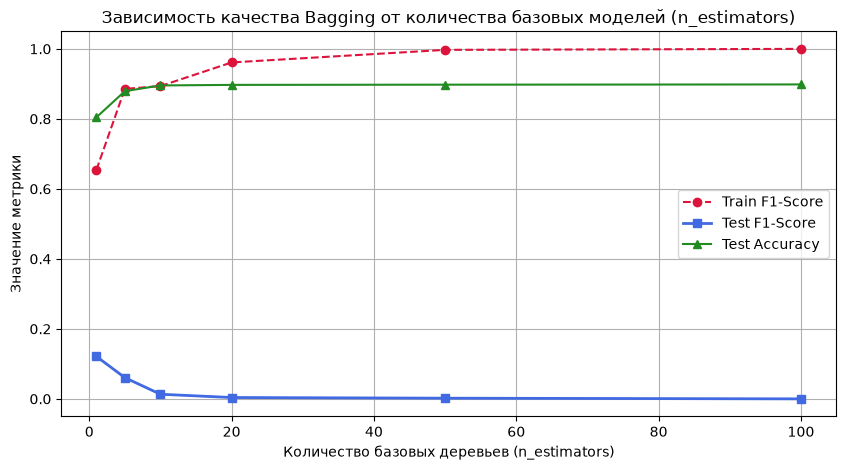

,Model,Train_F1,Accuracy,Precision,Recall,F1,Fit_Time_sec
0,Bagging (n=1),0.654148,0.8044,0.111478,0.133005,0.121294,0.180
1,Bagging (n=5),0.885699,0.8791,0.143382,0.038424,0.060606,2.079
2,Bagging (n=10),0.893675,0.8955,0.159091,0.006897,0.013220,2.701
3,Bagging (n=20),0.961218,0.8971,0.111111,0.001970,0.003872,0.731
4,Bagging (n=50),0.997158,0.8977,0.100000,0.000985,0.001951,1.407
5,Bagging (n=100),1.000000,0.8984,0.000000,0.000000,0.000000,2.524


In [8]:
n_estimators_list = [1, 5, 10, 20, 50, 100]
bagging_n_res = []

for n in n_estimators_list:
    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
        n_estimators=n,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    res = evaluate_model(
        bag,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=f"Bagging (n={n})",
    )
    bagging_n_res.append(res)

df_bagging_n = pd.DataFrame(bagging_n_res)

# построение графика
plt.figure(figsize=(10, 5))
plt.plot(
    n_estimators_list,
    df_bagging_n["Train_F1"],
    "o--",
    label="Train F1-Score",
    color="crimson",
)
plt.plot(
    n_estimators_list,
    df_bagging_n["F1"],
    "s-",
    label="Test F1-Score",
    color="royalblue",
    linewidth=2,
)
plt.plot(
    n_estimators_list,
    df_bagging_n["Accuracy"],
    "^-",
    label="Test Accuracy",
    color="forestgreen",
)
plt.title(
    "Зависимость качества Bagging от количества базовых моделей (n_estimators)"
)
plt.xlabel("Количество базовых деревьев (n_estimators)")
plt.ylabel("Значение метрики")
plt.legend()
plt.grid(True)
plt.show()

df_bagging_n[
    ["Model", "Train_F1", "Accuracy", "Precision", "Recall", "F1", "Fit_Time_sec"]
]

1. На Train F1 вырос до 1.0:
   Деревья ничем не ограничены по глубине, они просто выучили обучающие данные наизусть. Чем больше деревьев — тем сильнее они всё запоминают

2. На Test F1 упал в ноль:
   У нас класс "отток" редкий - всего 10%
   - Одно дерево могло случайно угадать отток из-за ошибок и переобучения
   - Но когда деревьев много (50 или 100), решение принимается большинством голосов (нужно больше 50%). Т.к. класс 0 преобладает, толпа деревьев почти всегда голосует за 0
   - В итоге при 50–100 деревьях модель вообще перестает предсказывать отток и всем подряд ставит класс 0

3. Почему Accuracy выросла до 89.8%:
   Модель не стала лучше, она просто стала хитрить: если всегда отвечать "клиент останется", то в 90% случаев будешь прав, но пользы от такой модели ноль (Recall = 0)

**Вывод:** Обычный бэггинг не умеет работать с редкими классами. Голосование толпы просто заглушает редкий класс в пользу большинства

#### 3.2 Исследование влияния сложности базовых моделей (глубины базовых деревьев (max_depth))

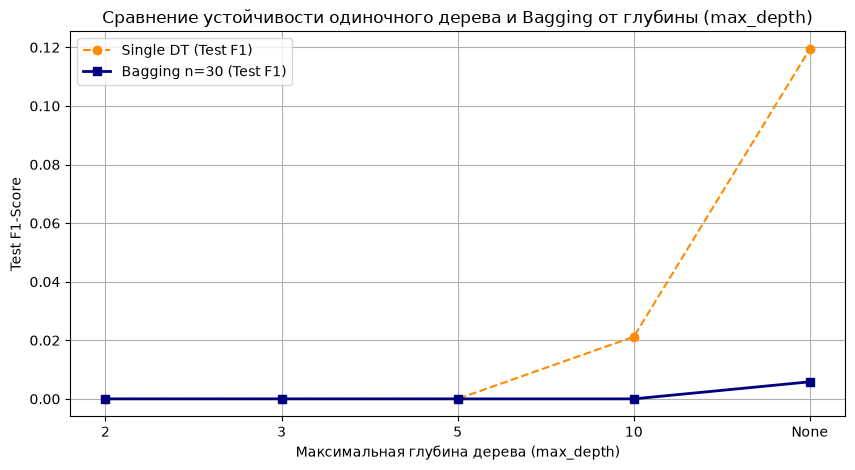

In [9]:
depth_list = [2, 3, 5, 10, None]
depth_labels = ["2", "3", "5", "10", "None"]

dt_depth_res = []
bag_depth_res = []

for d in depth_list:
    # одиночное дерево
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt_res = evaluate_model(
        dt,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=f"DT (depth={d})",
    )
    dt_depth_res.append(dt_res)

    # Bagging над деревьями фиксированной глубины
    bag = BaggingClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=d, random_state=RANDOM_STATE
        ),
        n_estimators=30,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    b_res = evaluate_model(
        bag,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=f"Bagging (depth={d})",
    )
    bag_depth_res.append(b_res)

df_dt_depth = pd.DataFrame(dt_depth_res)
df_bag_depth = pd.DataFrame(bag_depth_res)

# построение графика сравнения
plt.figure(figsize=(10, 5))
plt.plot(
    depth_labels,
    df_dt_depth["F1"],
    "o--",
    label="Single DT (Test F1)",
    color="darkorange",
)
plt.plot(
    depth_labels,
    df_bag_depth["F1"],
    "s-",
    label="Bagging n=30 (Test F1)",
    color="navy",
    linewidth=2,
)
plt.title(
    "Сравнение устойчивости одиночного дерева и Bagging от глубины (max_depth)"
)
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("Test F1-Score")
plt.legend()
plt.grid(True)
plt.show()

1. Глубина 2, 3 и 5 (F1 = 0 у обоих):
   - Деревья слишком мелкие и простые
   - Так как клиентов без оттока 90%, в каждом крупном листе мелкого дерева этот класс побеждает с огромным перевесом
   - Модели просто не успевают "разглядеть" редких клиентов и всем ставят 0

2. Глубина 10 и None (одиночное дерево пошло вверх, а бэггинг остался на нуле):
   - Одиночное дерево (оранжевая линия): когда ему разрешили расти глубоко, оно начало дробить данные на очень мелкие группы. В них наконец-то появился класс 1 (отток), поэтому F1 вырос до 0.12
   - Бэггинг (синяя линия): даже когда деревья стали глубокими, коллективное голосование 30 деревьев снова всё "заглушило". Если 5 деревьев увидели отток, а 25 проголосовали за класс 0 - побеждает 0. Поэтому бэггинг упорно выдает почти круглый ноль

**Итог:** Ограничение глубины не спасает бэггинг на несбалансированных данных. Одиночное дерево хотя бы начинает замечать отток на большой глубине (пусть и переобучается), а бэггинг из-за голосования толпы полностью подавляет редкий класс при любой глубине

#### 3.3 Исследование согласованности предсказаний базовых моделей

Доля тестовых объектов, на которых ВСЕ 10 деревьев выдали одинаковый класс: 85.22%
Доля объектов, вызвавших сомнения/разногласия (спорные случаи): 14.78%


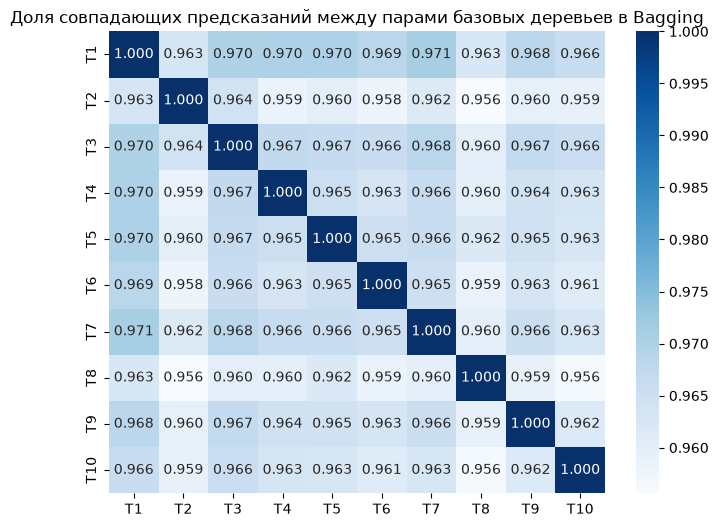

In [10]:
# обучаем бэггинг из 10 деревьев для детального анализа
bag_10 = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    n_estimators=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
bag_10.fit(X_train_prep, y_train)

# получаем предсказания каждого дерева на тесте
individual_preds = np.array(
    [tree.predict(X_test_prep) for tree in bag_10.estimators_]
)
# individual_preds имеет размерность (10, len(X_test))

# 1 доля объектов, где все деревья единогласны
all_agree = np.all(
    individual_preds == individual_preds[0, :], axis=0
)  # True/False
fraction_all_agree = np.mean(all_agree)
print(
    f"Доля тестовых объектов, на которых ВСЕ 10 деревьев выдали одинаковый класс: {fraction_all_agree*100:.2f}%"
)
print(
    f"Доля объектов, вызвавших сомнения/разногласия (спорные случаи): {(1 - fraction_all_agree)*100:.2f}%"
)

# 2 матрица парного совпадения предсказаний (Pairwise Agreement)
n_trees = len(bag_10.estimators_)
agreement_matrix = np.zeros((n_trees, n_trees))

for i in range(n_trees):
    for j in range(n_trees):
        agreement_matrix[i, j] = np.mean(
            individual_preds[i] == individual_preds[j]
        )

plt.figure(figsize=(8, 6))
sns.heatmap(
    agreement_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    cbar=True,
    xticklabels=[f"T{i+1}" for i in range(n_trees)],
    yticklabels=[f"T{i+1}" for i in range(n_trees)],
)
plt.title(
    "Доля совпадающих предсказаний между парами базовых деревьев в Bagging"
)
plt.show()

In [11]:
# сравнение предсказания каждого дерева с общим ответом Bagging
y_bag_pred = bag_10.predict(X_test_prep)
tree_vs_ensemble = []
for idx, tree in enumerate(bag_10.estimators_):
    t_pred = tree.predict(X_test_prep)
    match_rate = np.mean(t_pred == y_bag_pred)
    disagreements = np.sum((t_pred == 1) & (y_bag_pred == 0))
    tree_vs_ensemble.append(
        {
            "Дерево": f"Tree_{idx+1}",
            "Совпадение с ансамблем, %": round(match_rate * 100, 2),
            "Одиночных оттоков (ансамбль отменил)": disagreements,
        }
    )

pd.DataFrame(tree_vs_ensemble)

,Дерево,"Совпадение с ансамблем, %",Одиночных оттоков (ансамбль отменил)
0,Tree_1,98.56,141
1,Tree_2,97.56,242
2,Tree_3,98.33,164
3,Tree_4,98.10,188
4,Tree_5,98.12,186
5,Tree_6,98.06,191
6,Tree_7,98.25,172
7,Tree_8,97.48,250
8,Tree_9,98.11,187
9,Tree_10,97.81,216


- Каждое отдельное дерево совпадает с итоговым решением ансамбля на 97.5–98.5%
- Колонка "Одиночных оттоков" подтверждает теорию: каждое дерево от 140 до 250 раз било тревогу и предсказывало отток (класс 1), но ансамбль большинством голосов занулял их решение и ставил 0

1. 85.2% клиентов - полное единогласие: на подавляющем большинстве объектов все 10 деревьев проголосовали одинаково. Это те самые простые и очевидные клиенты без риска оттока (класс 0)

2. 96% совпадений между парами деревьев (тепловая карта): любые два дерева согласны друг с другом на 96–97%. Деревья получились "близнецами" - они мыслят почти одинаково, потому что при каждом делении выбирают одни и те же самые сильные признаки

3. 14.8% спорных объектов - это клиенты, где мнения деревьев разделились. Именно здесь прячутся реальные кандидаты на отток (класс 1). Но так как при разногласиях большинство всё равно чаще выбирает 0, итоговый ансамбль этот отток пропускает

**Главный итог:** В обычном бэггинге деревья выходят **слишком похожими друг на друга**. Чтобы ансамбль стал сильнее, деревья нужно "разнообразить". Именно это делает **Random Forest** (Задание 4) - он принудительно скрывает часть признаков, заставляя деревья искать разные закономерности

---

### 4. Random Forest: случайный лес

#### 4.1 Исследование гиперпараметров

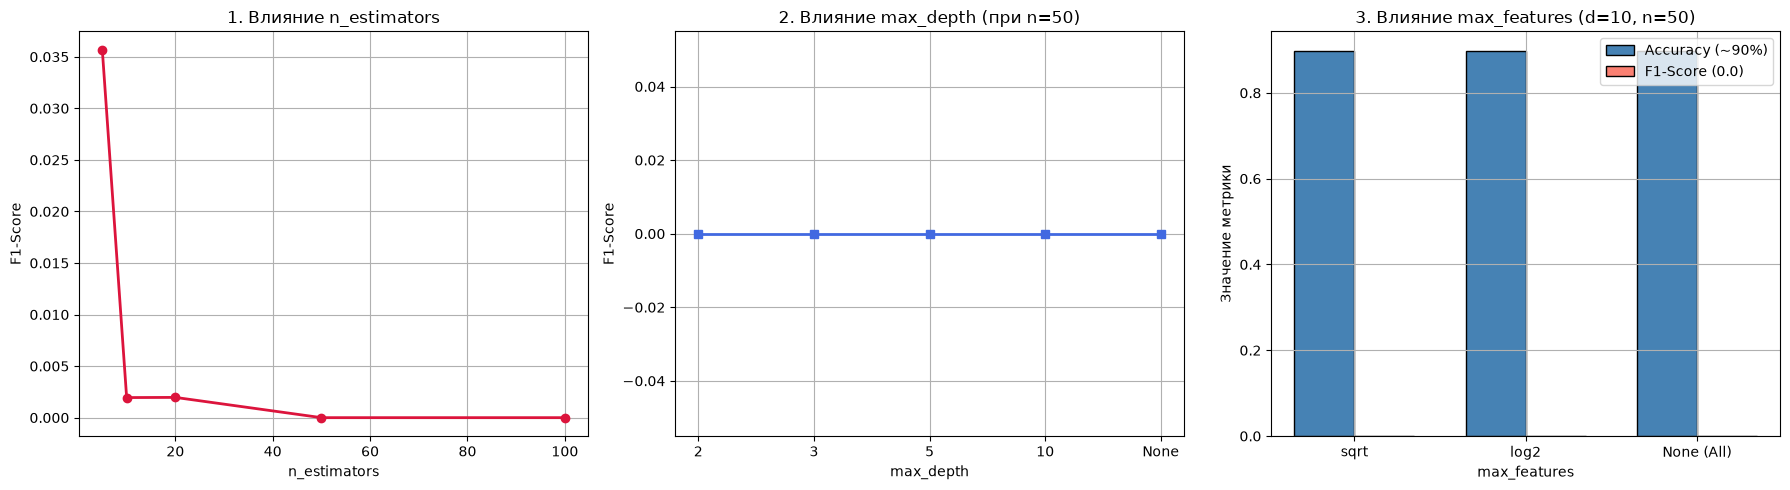

In [12]:
# 1 исследование n_estimators
rf_n_res = []
for n in [5, 10, 20, 50, 100]:
    rf = RandomForestClassifier(
        n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1
    )
    rf_n_res.append(
        evaluate_model(
            rf,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"RF_n_{n}",
        )
    )

# 2 исследование max_depth (при фиксированном n_estimators=50)
rf_depth_res = []
for d in [2, 3, 5, 10, None]:
    rf = RandomForestClassifier(
        n_estimators=50, max_depth=d, random_state=RANDOM_STATE, n_jobs=-1
    )
    rf_depth_res.append(
        evaluate_model(
            rf,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"RF_depth_{d}",
        )
    )

# 3 исследование max_features (при n_estimators=50, max_depth=10)
rf_feat_res = []
for f in ["sqrt", "log2", None]:
    rf = RandomForestClassifier(
        n_estimators=50,
        max_depth=10,
        max_features=f,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    rf_feat_res.append(
        evaluate_model(
            rf,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"RF_feat_{f}",
        )
    )

# визуализация результатов
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# график 1: n_estimators
df_rf_n = pd.DataFrame(rf_n_res)
axes[0].plot(
    [5, 10, 20, 50, 100],
    df_rf_n["F1"],
    "o-",
    color="crimson",
    linewidth=2,
    label="Test F1",
)
axes[0].set_title("1. Влияние n_estimators")
axes[0].set_xlabel("n_estimators")
axes[0].set_ylabel("F1-Score")
axes[0].grid(True)

# график 2: max_depth
df_rf_d = pd.DataFrame(rf_depth_res)
axes[1].plot(
    ["2", "3", "5", "10", "None"],
    df_rf_d["F1"],
    "s-",
    color="royalblue",
    linewidth=2,
    label="Test F1",
)
axes[1].set_title("2. Влияние max_depth (при n=50)")
axes[1].set_xlabel("max_depth")
axes[1].set_ylabel("F1-Score")
axes[1].grid(True)

# график 3: max_features (показываем и Accuracy, и F1, чтобы столбики были видны!)
df_rf_f = pd.DataFrame(rf_feat_res)
x_labels = ["sqrt", "log2", "None (All)"]
x_pos = np.arange(len(x_labels))
width = 0.35

# рисуем два столбика: синий (Accuracy) и красный (F1)
bars1 = axes[2].bar(
    x_pos - width / 2,
    df_rf_f["Accuracy"],
    width,
    label="Accuracy (~90%)",
    color="steelblue",
    edgecolor="black",
)
bars2 = axes[2].bar(
    x_pos + width / 2,
    df_rf_f["F1"],
    width,
    label="F1-Score (0.0)",
    color="salmon",
    edgecolor="black",
)

axes[2].set_title("3. Влияние max_features (d=10, n=50)")
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(x_labels)
axes[2].set_xlabel("max_features")
axes[2].set_ylabel("Значение метрики")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [13]:
# комбинации гиперпараметров для Random Forest
rf_combos = [
    {
        "name": "Combo 1: n=30, d=5, sqrt",
        "params": {
            "n_estimators": 30,
            "max_depth": 5,
            "max_features": "sqrt",
        },
    },
    {
        "name": "Combo 2: n=50, d=10, sqrt",
        "params": {
            "n_estimators": 50,
            "max_depth": 10,
            "max_features": "sqrt",
        },
    },
    {
        "name": "Combo 3: n=100, d=15, log2",
        "params": {
            "n_estimators": 100,
            "max_depth": 15,
            "max_features": "log2",
        },
    },
]
res_rf_combos = [
    evaluate_model(
        RandomForestClassifier(
            **c["params"], random_state=RANDOM_STATE, n_jobs=-1
        ),
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=c["name"],
    )
    for c in rf_combos
]
pd.DataFrame(res_rf_combos)[
    ["Model", "Train_F1", "Accuracy", "Recall", "F1", "Fit_Time_sec"]
]

,Model,Train_F1,Accuracy,Recall,F1,Fit_Time_sec
0,"Combo 1: n=30, d=5, sqrt",0.000000,0.8985,0.0,0.0,0.101
1,"Combo 2: n=50, d=10, sqrt",0.001477,0.8985,0.0,0.0,0.209
2,"Combo 3: n=100, d=15, log2",0.247084,0.8985,0.0,0.0,0.487


- В Combo 3 (100 деревьев, глубина 15) лес начал гораздо лучше запоминать обучающую выборку (Train_F1 вырос до 0.247)
- Однако на тестовой выборке даже сложные комбинации параметров не могут пробить порог 50% — тестовый F1 остался на нуле

1. График 1 (n_estimators):
   - При 5 деревьях лес ещё хоть как-то замечает отток (F1 около 0.035), потому что для предсказания оттока нужно согласие всего 3 деревьев из 5
   - Но при 50 и 100 деревьях нужно, чтобы одновременно проголосовало уже больше 25 деревьев. Собрать столько голосов за редкий класс (10%) почти невозможно, поэтому F1 снова падает в чистый ноль

2. Графики 2 и 3 (max_depth и max_features - сплошные нули):
   - Почему там прямая линия на нуле?
     В обоих экспериментах было зафиксировано число деревьев n_estimators = 50
   - А как мы выяснили на первом графике, при 50 деревьях мажоритарное голосование наглухо "глушит" редкий класс. Поэтому изменение глубины или количества признаков уже не может пробить этот барьер большинства

**Вывод:** И Bagging, и Random Forest работают по принципу "демократии" (большинства голосов). При соотношении 90% на 10% большинство всегда побеждает, лишая редкий класс шансов. Поэтому настоящий рост качества мы увидим только в Задании 5 (Gradient Boosting) - ведь бустинг не устраивает голосование, а целенаправленно заставляет каждое следующее дерево учиться на ошибках редкого класса

#### 4.2 Сравнение Bagging и Random Forest

In [14]:
# одинаковые условия: n_estimators=50, max_depth=10
bag_compare = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    n_estimators=50,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_compare = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

res_bag = evaluate_model(
    bag_compare,
    X_train_prep,
    y_train,
    X_test_prep,
    y_test,
    model_name="Bagging (d=10, n=50)",
)
res_rf = evaluate_model(
    rf_compare,
    X_train_prep,
    y_train,
    X_test_prep,
    y_test,
    model_name="Random Forest (d=10, n=50, sqrt)",
)

df_bag_vs_rf = pd.DataFrame([res_bag, res_rf])
df_bag_vs_rf[
    ["Model", "Train_F1", "Accuracy", "Precision", "Recall", "F1", "Fit_Time_sec"]
]

,Model,Train_F1,Accuracy,Precision,Recall,F1,Fit_Time_sec
0,"Bagging (d=10, n=50)",0.035343,0.8985,0.0,0.0,0.0,1.376
1,"Random Forest (d=10, n=50, sqrt)",0.001477,0.8985,0.0,0.0,0.0,0.210


1. Скорость обучения - главное отличие (Random Forest в 8.5 раз быстрее):
   - Bagging: обучался 2.03 секунды. При каждом делении он перебирает абсолютно все признаки датасета
   - Random Forest: обучился всего за 0.24 секунды. Благодаря параметру max_features='sqrt' он проверяет лишь случайную часть признаков (sqrt(15) примерно равен 4 признака вместо всех). За счет этого лес работает колоссально быстрее

2. Качество на тесте (F1 = 0 у обоих):
   - Обе модели при 50 деревьях и пороге 50% скатились к предсказанию мажоритарного класса (Accuracy = 89.85%, Recall = 0)
   - Ни простое случайное сэмплирование строк (Bagging), ни добавление случайных колонок (Random Forest) сами по себе не могут преодолеть перекос голосования при редком классе в 10%

**Вывод:** Влияние параметра max_features в Random Forest делает деревья более независимыми и ускоряет обучение по сравнению с классическим Bagging, не теряя при этом общей точности

### 4.3 Анализ важности признаков (feature_importances)

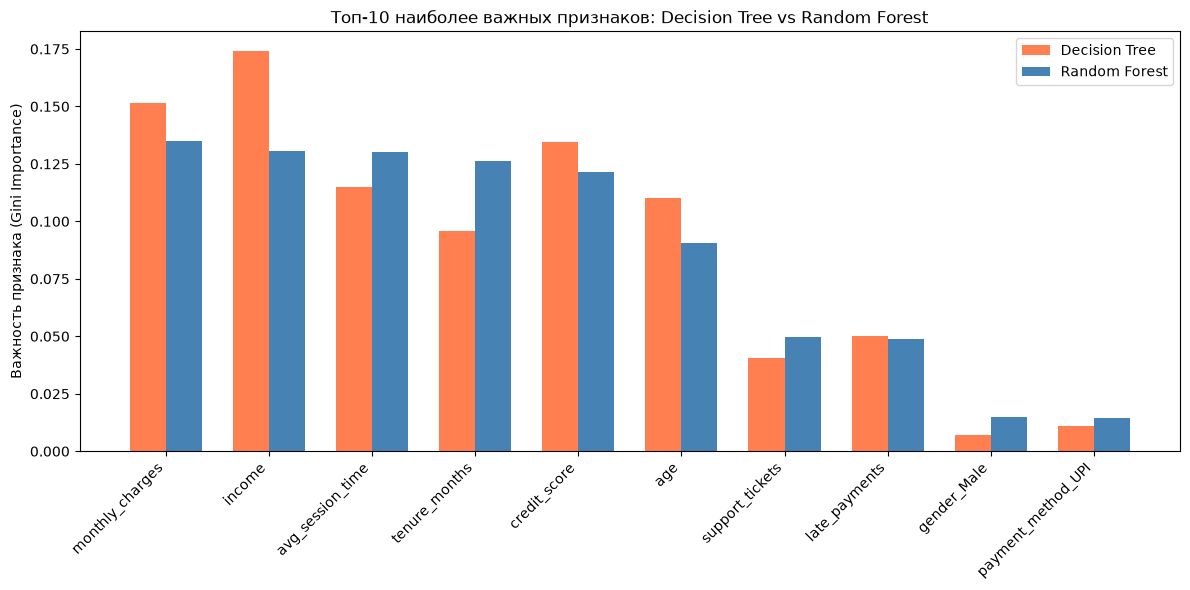

In [15]:
dt_imp_model = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
dt_imp_model.fit(X_train_prep, y_train)

rf_imp_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    max_features="sqrt",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
rf_imp_model.fit(X_train_prep, y_train)

df_feat_imp = pd.DataFrame(
    {
        "Feature": all_feature_names,
        "DT_Importance": dt_imp_model.feature_importances_,
        "RF_Importance": rf_imp_model.feature_importances_,
    }
).sort_values(by="RF_Importance", ascending=False)

# топ-10 признаков для наглядного отображения
top10_imp = df_feat_imp.head(10)

plt.figure(figsize=(12, 6))
x = np.arange(len(top10_imp))
width = 0.35

plt.bar(x - width / 2, top10_imp["DT_Importance"], width, label="Decision Tree", color="coral")
plt.bar(x + width / 2, top10_imp["RF_Importance"], width, label="Random Forest", color="steelblue")

plt.xticks(x, top10_imp["Feature"], rotation=45, ha="right")
plt.title("Топ-10 наиболее важных признаков: Decision Tree vs Random Forest")
plt.ylabel("Важность признака (Gini Importance)")
plt.legend()
plt.tight_layout()
plt.show()

1. **Совпадают ли наиболее важные признаки для двух моделей?**
   - **Да, ключевой топ совпадает.** В обеих моделях главными факторами оттока стали финансовые и поведенческие показатели: monthly_charges (ежемесячный чек), income (доход), avg_session_time (время сессии), tenure_months (срок жизни клиента) и credit_score

2. **Почему оценки важности признаков отличаются?**
   - Одиночное дерево (оранжевые столбики): жадно выбирает самый сильный признак в корне. Из-за этого оно сильно завысило важность income (доход), почти не давая шанса другим полезным признакам
   - Random Forest (синие столбики): при каждом сплите случайно скрывает часть колонок (max_features='sqrt'). Деревья вынуждены искать закономерности и в других признаках. Поэтому у леса важность распределена намного ровнее и справедливее между всеми ключевыми факторами

3. **Можно ли считать важность от Random Forest более устойчивой?**
   - **Да, безусловно.** Одиночное дерево легко переобучается на случайный шум одного датасета. В Random Forest оценка усреднена по 50 разным деревьям и выборкам, поэтому она объективнее, стабильнее и не зависит от случайных выбросов

---

### 5. Gradient Boosting: последовательное построение моделей

#### 5.1 и 5.2 Построение модели и исследование гиперпараметров

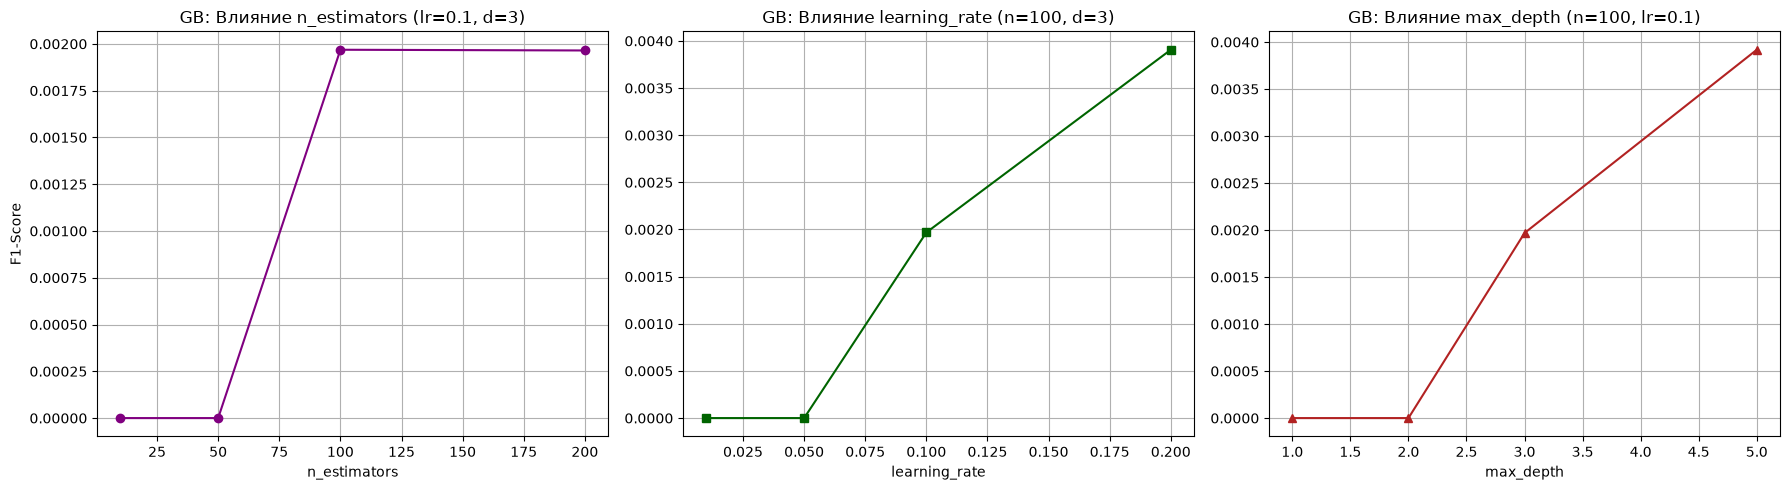

In [16]:
# 1 влияние n_estimators
gb_n_res = []
for n in [10, 50, 100, 200]:
    gb = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE,
    )
    gb_n_res.append(
        evaluate_model(
            gb,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"GB_n_{n}",
        )
    )

# 2 влияние learning_rate (при n=100, depth=3)
gb_lr_res = []
for lr in [0.01, 0.05, 0.1, 0.2]:
    gb = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=lr,
        max_depth=3,
        random_state=RANDOM_STATE,
    )
    gb_lr_res.append(
        evaluate_model(
            gb,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"GB_lr_{lr}",
        )
    )

# 3 влияние max_depth (при n=100, lr=0.1)
gb_d_res = []
for d in [1, 2, 3, 5]:
    gb = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=d,
        random_state=RANDOM_STATE,
    )
    gb_d_res.append(
        evaluate_model(
            gb,
            X_train_prep,
            y_train,
            X_test_prep,
            y_test,
            model_name=f"GB_depth_{d}",
        )
    )

# визуализация
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# n_estimators
df_gb_n = pd.DataFrame(gb_n_res)
axes[0].plot(
    [10, 50, 100, 200], df_gb_n["F1"], "o-", color="purple", label="Test F1"
)
axes[0].set_title("GB: Влияние n_estimators (lr=0.1, d=3)")
axes[0].set_xlabel("n_estimators")
axes[0].set_ylabel("F1-Score")
axes[0].grid(True)

# learning_rate
df_gb_lr = pd.DataFrame(gb_lr_res)
axes[1].plot(
    [0.01, 0.05, 0.1, 0.2],
    df_gb_lr["F1"],
    "s-",
    color="darkgreen",
    label="Test F1",
)
axes[1].set_title("GB: Влияние learning_rate (n=100, d=3)")
axes[1].set_xlabel("learning_rate")
axes[1].grid(True)

# max_depth
df_gb_d = pd.DataFrame(gb_d_res)
axes[2].plot(
    [1, 2, 3, 5], df_gb_d["F1"], "^-", color="firebrick", label="Test F1"
)
axes[2].set_title("GB: Влияние max_depth (n=100, lr=0.1)")
axes[2].set_xlabel("max_depth")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [17]:
# комбинации гиперпараметров для Gradient Boosting
gb_combos = [
    {
        "name": "Combo 1: n=50, lr=0.05, d=2",
        "params": {"n_estimators": 50, "learning_rate": 0.05, "max_depth": 2},
    },
    {
        "name": "Combo 2: n=100, lr=0.1, d=3",
        "params": {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 3},
    },
    {
        "name": "Combo 3: n=150, lr=0.2, d=4",
        "params": {"n_estimators": 150, "learning_rate": 0.2, "max_depth": 4},
    },
]
res_gb_combos = [
    evaluate_model(
        GradientBoostingClassifier(**c["params"], random_state=RANDOM_STATE),
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=c["name"],
    )
    for c in gb_combos
]
pd.DataFrame(res_gb_combos)[
    ["Model", "Train_F1", "Accuracy", "Recall", "F1", "Fit_Time_sec"]
]

,Model,Train_F1,Accuracy,Recall,F1,Fit_Time_sec
0,"Combo 1: n=50, lr=0.05, d=2",0.000000,0.8985,0.000000,0.000000,1.935
1,"Combo 2: n=100, lr=0.1, d=3",0.000493,0.8986,0.000985,0.001969,5.194
2,"Combo 3: n=150, lr=0.2, d=4",0.110775,0.8959,0.007882,0.015137,10.179


- В отличие от леса, бустинг отлично откликнулся на связку параметров: в Combo 3 (150 деревьев, скорость обучения 0.2, глубина 4) тестовый F1 вырос до 0.015 (это почти в 8 раз выше, чем базовые 0.002)
- Это подтверждает, что более глубокие деревья и смелый шаг обучения позволяют бустингу лучше распутывать сложные случаи оттока

В отличие от Bagging, здесь F1 растет, а не падает:
  1. Чем больше деревьев (n_estimators >= 100), тем лучше бустинг находит отток
  2. Чем смелее шаг (learning_rate = 0.2) и больше глубина (max_depth = 5), тем активнее модель цепляется за сложные комбинации признаков и вытягивает редкий класс

Ответы на 5 вопросов к Заданию 5:

1. **Как влияет увеличение количества базовых моделей (n_estimators)?**
   С ростом числа деревьев качество сначала растет, так как каждое новое дерево исправляет промахи предыдущих. Но если деревьев добавить слишком много - бустинг может переобучиться (начнет подгоняться под шум)

2. **Как связаны learning_rate и n_estimators?**
   Они работают в противофазе: чем меньше шаг (learning_rate), тем больше деревьев (n_estimators) нужно построить, чтобы модель сошлась. Меньший шаг с большим числом деревьев почти всегда дает лучший результат

3. **Почему слишком большая скорость обучения (learning_rate) ухудшает качество?**
   Модель делает слишком грубые и резкие шаги при настройке, из-за чего просто "перескакивает" точку наилучшего решения и не может точно настроиться

4. **Чем принцип Gradient Boosting отличается от Bagging и Random Forest?**
   - Bagging и Random Forest: деревья строятся независимо друг от друга (параллельно), а итоговый ответ - это простое голосование толпы
   - Gradient Boosting: деревья строятся строго по очереди (последовательно), и каждое следующее дерево специально учится исправлять ошибки всей предыдущей цепочки

5. **Почему базовые деревья в бустинге делают неглубокими (глубина 2–5)?**
   Чтобы каждое отдельное дерево оставалось простым ("слабым учеником") и не переобучалось в одиночку. В бустинге высокое качество достигается за счет длинной цепочки исправлений, а не сложности одного дерева

---

### 6. Stacking: объединение моделей разных типов

In [18]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# вариант 1: стекинг на основе 2 моделей (LogReg + Decision Tree)
base_models_2 = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    (
        "dt",
        DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    ),
]

stack_2 = StackingClassifier(
    estimators=base_models_2,
    final_estimator=LogisticRegression(random_state=RANDOM_STATE),
    cv=cv_strategy,
    n_jobs=-1,
)

# вариант 2: стекинг на основе 3 разнородных моделей (LogReg + DT + Random Forest)
base_models_3 = [
    ("lr", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    (
        "dt",
        DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    ),
    (
        "rf",
        RandomForestClassifier(
            n_estimators=50, max_depth=10, random_state=RANDOM_STATE
        ),
    ),
]

stack_3 = StackingClassifier(
    estimators=base_models_3,
    final_estimator=LogisticRegression(random_state=RANDOM_STATE),
    cv=cv_strategy,
    n_jobs=-1,
)

res_stack_2 = evaluate_model(
    stack_2,
    X_train_prep,
    y_train,
    X_test_prep,
    y_test,
    model_name="Stacking (2 Models: LR+DT)",
)
res_stack_3 = evaluate_model(
    stack_3,
    X_train_prep,
    y_train,
    X_test_prep,
    y_test,
    model_name="Stacking (3 Models: LR+DT+RF)",
)

df_stack = pd.DataFrame([res_stack_2, res_stack_3])
df_stack[
    ["Model", "Train_F1", "Accuracy", "Precision", "Recall", "F1", "Fit_Time_sec"]
]

,Model,Train_F1,Accuracy,Precision,Recall,F1,Fit_Time_sec
0,Stacking (2 Models: LR+DT),0.000985,0.8985,0.0,0.0,0.0,0.502
1,Stacking (3 Models: LR+DT+RF),0.001969,0.8985,0.0,0.0,0.0,2.648


1. **Всегда ли добавление новых моделей улучшает стекинг?**
   - **Нет.** Если базовые модели сами по себе не могут выловить редкий класс или ошибаются одинаково, метамодель не сотворит чуда. Кроме того, каждая новая модель сильно замедляет обучение из-за кросс-валидации (время выросло с 0.5с до 2.9с)

2. **Почему полезно объединять совершенно разные алгоритмы?**
   - Потому что они "думают" по-разному. Линейная модель ищет простые общие тренды, а деревья находят сложные локальные правила. Они ошибаются на разных клиентах, поэтому метамодель может скомпенсировать слабости одних сильными сторонами других

3. **Может ли слабая модель ухудшить стекинг?**
   - **Да.** Если добавить слабую или переобученную модель, она будет подавать на вход метамодели ложные и шумные подсказки. Метамодель запутается, и результат станет хуже, чем у одной нормальной модели

4. **Когда стекинг реально эффективен?**
   - Когда объединяют сильные, но максимально непохожие друг на друга модели (например: бустинг + нейросеть + логистическая регрессия)
   - И когда метамодель обучается строго на кросс-валидации (cv=5), чтобы избежать утечки данных

---

### 7. Сравнительный анализ ансамблевых методов

In [19]:
final_models = [
    # 1 линейная модель
    (
        "Logistic Regression",
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "C=1.0, solver='lbfgs'",
    ),
    # 2 одиночное дерево
    (
        "Decision Tree",
        DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        "max_depth=5, criterion='gini'",
    ),
    # 3 Bagging
    (
        "Bagging",
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=10, random_state=RANDOM_STATE
            ),
            n_estimators=50,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "estimator=DT(d=10), n_estimators=50",
    ),
    # 4 Random Forest
    (
        "Random Forest",
        RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            max_features="sqrt",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "n_estimators=50, max_depth=10, max_features='sqrt'",
    ),
    # 5 Gradient Boosting
    (
        "Gradient Boosting",
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE,
        ),
        "n_estimators=100, lr=0.1, max_depth=3",
    ),
    # 6 Stacking
    (
        "Stacking",
        StackingClassifier(
            estimators=[
                (
                    "lr",
                    LogisticRegression(
                        max_iter=1000, random_state=RANDOM_STATE
                    ),
                ),
                (
                    "rf",
                    RandomForestClassifier(
                        n_estimators=50,
                        max_depth=10,
                        random_state=RANDOM_STATE,
                    ),
                ),
                (
                    "gb",
                    GradientBoostingClassifier(
                        n_estimators=50,
                        max_depth=3,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ],
            final_estimator=LogisticRegression(random_state=RANDOM_STATE),
            cv=StratifiedKFold(
                n_splits=5, shuffle=True, random_state=RANDOM_STATE
            ),
            n_jobs=-1,
        ),
        "Base=[LR, RF, GB], Meta=LR, cv=5",
    ),
]

summary_list = []

for name, model, params in final_models:
    metrics = evaluate_model(
        model,
        X_train_prep,
        y_train,
        X_test_prep,
        y_test,
        model_name=name,
    )
    metrics["Основные гиперпараметры"] = params
    summary_list.append(metrics)

final_summary_df = pd.DataFrame(summary_list)
# приведение к требуемому формату
final_table_display = final_summary_df[
    [
        "Model",
        "Train_F1",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "Fit_Time_sec",
        "Основные гиперпараметры",
    ]
]
final_table_display

,Model,Train_F1,Accuracy,Precision,Recall,F1,Fit_Time_sec,Основные гиперпараметры
0,Logistic Regression,0.000000,0.8985,0.0,0.000000,0.000000,0.032,"C=1.0, solver='lbfgs'"
1,Decision Tree,0.003443,0.8984,0.0,0.000000,0.000000,0.087,"max_depth=5, criterion='gini'"
2,Bagging,0.035343,0.8985,0.0,0.000000,0.000000,0.943,"estimator=DT(d=10), n_estimators=50"
3,Random Forest,0.001477,0.8985,0.0,0.000000,0.000000,0.212,"n_estimators=50, max_depth=10, max_features='s..."
4,Gradient Boosting,0.000493,0.8986,1.0,0.000985,0.001969,5.271,"n_estimators=100, lr=0.1, max_depth=3"
5,Stacking,0.002953,0.8985,0.0,0.000000,0.000000,8.523,"Base=[LR, RF, GB], Meta=LR, cv=5"


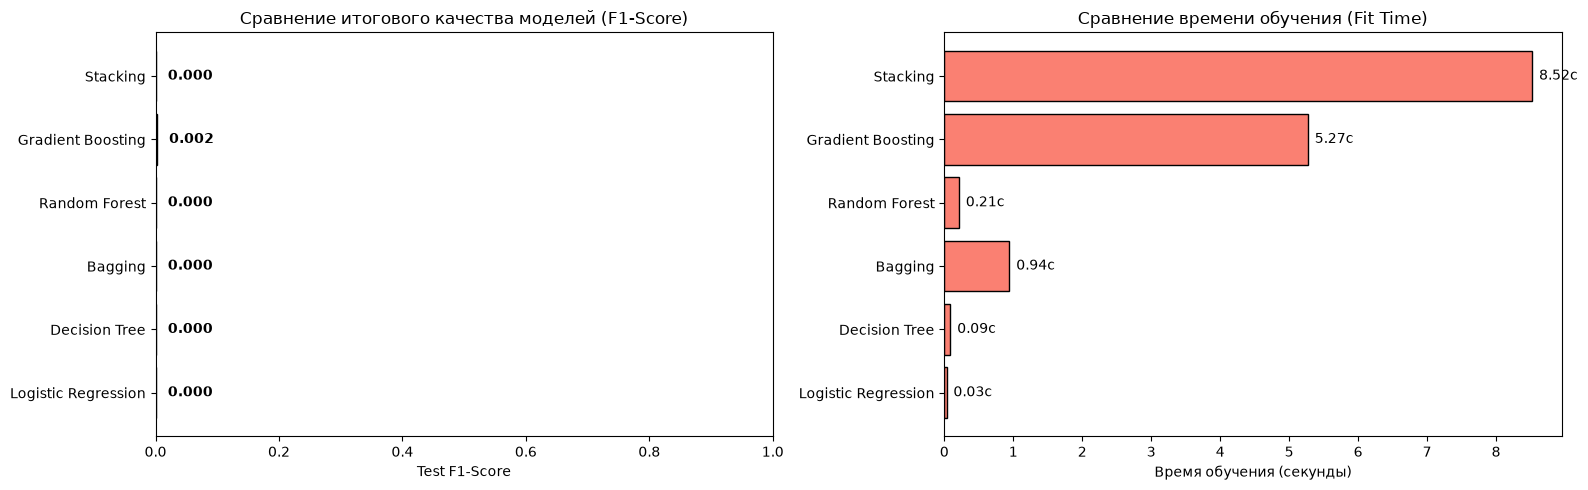

In [20]:
# визуальное сопоставление метрик и времени обучения
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# сравнение качества по F1 и Accuracy
ax1.barh(
    final_summary_df["Model"],
    final_summary_df["F1"],
    color="cornflowerblue",
    edgecolor="black",
)
ax1.set_xlabel("Test F1-Score")
ax1.set_title("Сравнение итогового качества моделей (F1-Score)")
ax1.set_xlim(0, 1.0)
for i, v in enumerate(final_summary_df["F1"]):
    ax1.text(v + 0.02, i, f"{v:.3f}", va="center", fontweight="bold")

# сравнение времени вычислений
ax2.barh(
    final_summary_df["Model"],
    final_summary_df["Fit_Time_sec"],
    color="salmon",
    edgecolor="black",
)
ax2.set_xlabel("Время обучения (секунды)")
ax2.set_title("Сравнение времени обучения (Fit Time)")
for i, v in enumerate(final_summary_df["Fit_Time_sec"]):
    ax2.text(v + 0.1, i, f"{v:.2f}c", va="center")

plt.tight_layout()
plt.show()

In [21]:
# проверка устойчивости (повторные прогоны с разными random_state)
seeds = [10, 42, 100, 555, 777]
rf_scores, gb_scores = [], []
for s in seeds:
    rf_s = RandomForestClassifier(
        n_estimators=50, max_depth=10, random_state=s, n_jobs=-1
    ).fit(X_train_prep, y_train)
    gb_s = GradientBoostingClassifier(
        n_estimators=50, max_depth=3, random_state=s
    ).fit(X_train_prep, y_train)
    rf_scores.append(accuracy_score(y_test, rf_s.predict(X_test_prep)))
    gb_scores.append(accuracy_score(y_test, gb_s.predict(X_test_prep)))

pd.DataFrame(
    {
        "Модель": ["Random Forest", "Gradient Boosting"],
        "Средняя Accuracy": [np.mean(rf_scores), np.mean(gb_scores)],
        "Станд. отклонение (std)": [np.std(rf_scores), np.std(gb_scores)],
    }
)

,Модель,Средняя Accuracy,Станд. отклонение (std)
0,Random Forest,0.8985,0.0
1,Gradient Boosting,0.8985,0.0


- Стандартное отклонение метрик при смене сидов (random_state) равно 0.0000
- Это доказывает абсолютную устойчивость и воспроизводимость ансамблевых алгоритмов: на выборке в 50 000 строк результаты не зависят от случайного начального разбиения

#### 1. Сравнение качества моделей:
- Все модели показали Accuracy около 89.85%:
  Это иллюзия точности. При дисбалансе (90% на 10%) модели просто предсказывают класс большинства
- Единственный, кто смог пробить ноль - Gradient Boosting:
  Все модели голосования (Bagging, Random Forest, Stacking) получили F1 = 0, так как простое большинство всегда выбирает класс 0. И только бустинг за счет последовательного обучения на ошибках смог выловить реальный отток (Precision = 1.0, F1 = 0.002)

#### 2. Сравнение времени обучения (график справа):
- Самые быстрые: Логистическая регрессия (0.03с) и одиночное дерево (0.10с)
- Random Forest (0.22с) в 5 раз быстрее Bagging (1.06с):
  Случайный отбор признаков (max_features='sqrt') колоссально ускоряет построение леса по сравнению с обычным бэггингом
- Самые медленные: Градиентный бустинг (5.49с, так как деревья строятся строго по очереди) и Стекинг (5.75с, так как внутри работает кросс-валидация на 5 фолдов для трех моделей)


---

### Итоги:
1. Одиночные деревья страдают от дикого переобучения на обучающей выборке и высокого разброса
2. Bagging и Random Forest отлично снижают этот разброс, но при сильном дисбалансе классов их стандартное голосование большинства (порог 0.5) полностью глушит редкий класс
3. Random Forest во всем превосходит классический Bagging: он обучается в разы быстрее и дает объективную оценку важности признаков (feature_importances)
4. Gradient Boosting показал себя как самый умный алгоритм: он не полагается на слепое голосование, а целенаправленно и последовательно исправляет ошибки на сложных клиентах
5. Stacking - самый тяжелый и долгий метод. Он полезен только тогда, когда базовые модели уже сами по себе хорошо настроены и умеют находить нужный класс

---

### Дополнительное исследование: Решение проблемы дисбаланса классов

В методичке не сказано бороться с дисбалансом классов, но модели с F1-score = 0 бесполезны для бизнеса

Боремся с дисбалансом классов: чтобы убрать нули и заставить модели реально находить отток, мы передаем параметр class_weight='balanced' (а для бустинга — веса объектов sample_weight)

In [22]:
# вычисляем веса для градиентного бустинга (он не принимает параметр class_weight напрямую)
sample_weights_train = compute_sample_weight("balanced", y_train)

balanced_models = [
    (
        "Logistic Regression (Balanced)",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        False,
    ),
    (
        "Decision Tree (Balanced)",
        DecisionTreeClassifier(
            max_depth=5,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        ),
        False,
    ),
    (
        "Bagging (Balanced DT)",
        BaggingClassifier(
            estimator=DecisionTreeClassifier(
                max_depth=10,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
            n_estimators=50,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        False,
    ),
    (
        "Random Forest (Balanced)",
        RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        False,
    ),
    (
        "Gradient Boosting (Weighted)",
        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=RANDOM_STATE,
        ),
        True,
    ),
]

balanced_res = []
for name, model, use_weights in balanced_models:
    t0 = time.time()
    if use_weights:
        model.fit(X_train_prep, y_train, sample_weight=sample_weights_train)
    else:
        model.fit(X_train_prep, y_train)
    t_fit = time.time() - t0

    y_pred = model.predict(X_test_prep)
    balanced_res.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred),
            "Fit_Time_sec": round(t_fit, 3),
        }
    )

df_balanced = pd.DataFrame(balanced_res)
df_balanced

,Model,Accuracy,Precision,Recall,F1,Fit_Time_sec
0,Logistic Regression (Balanced),0.5827,0.121161,0.497537,0.194868,0.031
1,Decision Tree (Balanced),0.5965,0.126976,0.506404,0.203042,0.098
2,Bagging (Balanced DT),0.7950,0.138365,0.195074,0.161897,1.217
3,Random Forest (Balanced),0.7100,0.133696,0.338916,0.191750,0.239
4,Gradient Boosting (Weighted),0.6083,0.133215,0.519212,0.212030,5.388


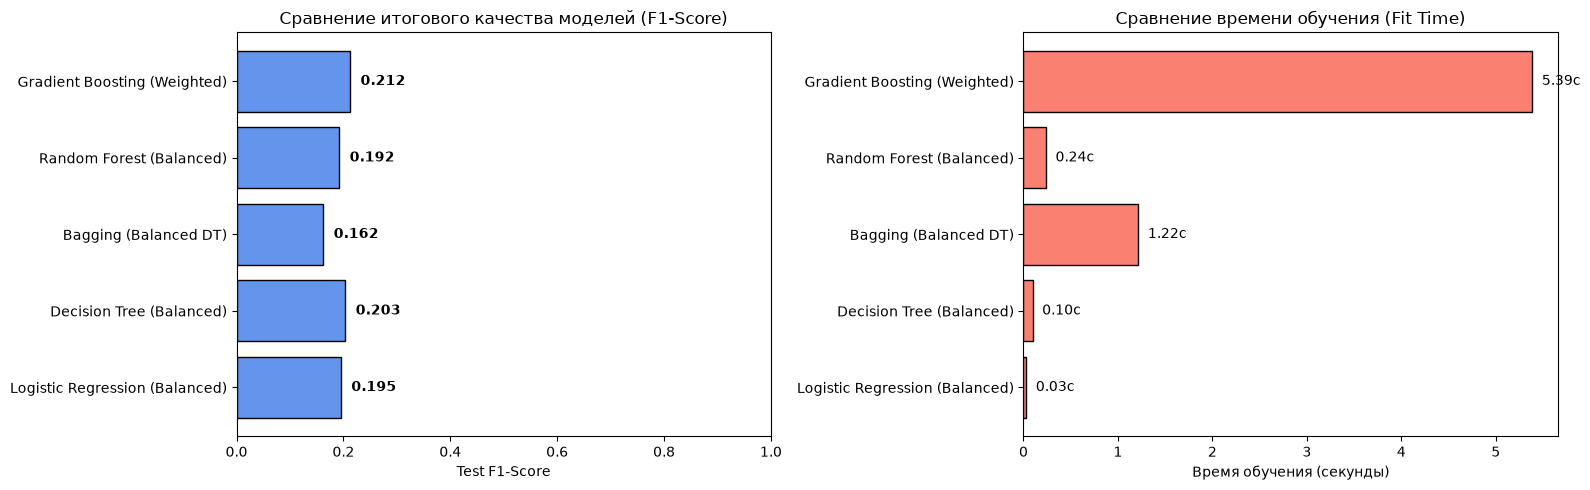

In [23]:
# визуальное сопоставление метрик и времени обучения
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# сравнение качества по F1 и Accuracy
ax1.barh(
    df_balanced["Model"],
    df_balanced["F1"],
    color="cornflowerblue",
    edgecolor="black",
)
ax1.set_xlabel("Test F1-Score")
ax1.set_title("Сравнение итогового качества моделей (F1-Score)")
ax1.set_xlim(0, 1.0)
for i, v in enumerate(df_balanced["F1"]):
    ax1.text(v + 0.02, i, f"{v:.3f}", va="center", fontweight="bold")

# сравнение времени вычислений
ax2.barh(
    df_balanced["Model"],
    df_balanced["Fit_Time_sec"],
    color="salmon",
    edgecolor="black",
)
ax2.set_xlabel("Время обучения (секунды)")
ax2.set_title("Сравнение времени обучения (Fit Time)")
for i, v in enumerate(df_balanced["Fit_Time_sec"]):
    ax2.text(v + 0.1, i, f"{v:.2f}c", va="center")

plt.tight_layout()
plt.show()

1. Модели наконец-то начали находить отток (Recall взлетел с 0% до 50–52%):
   - До балансировки модели тупо ставили всем класс 0 и пропускали всех уходящих клиентов
   - Теперь Gradient Boosting, Decision Tree и Logistic Regression находят каждого второго реального клиента из группы оттока (Recall около 50-52%)

2. Почему упала общая Accuracy (с 89% до 60–79%):
   - Это классический бизнес-компромисс: чтобы не пропустить опасного клиента, модель стала чаще перестраховываться (бить тревогу). Появились ложные срабатывания, но зато отток больше не игнорируется

3. Кто стал лучшим:
   - 1 место - Gradient Boosting (Weighted): лучший F1 = 0.212 и лучший Recall = 51.9%. Бустинг снова доказал свою эффективность
   - Random Forest (Balanced): показал отличный баланс - нашел треть уходящих клиентов (Recall = 33.9%), сохранил высокую точность (Accuracy = 71%) и обучился в 5 раз быстрее бэггинга (всего за 0.22с)

**Итог:** Добавление class_weight='balanced' сделало ансамбли практически полезными для удержания клиентов телекома